<a href="https://colab.research.google.com/github/KazumasRook/tractprojectcsv/blob/main/Individualof_HC_7_Borough_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#HC7 - Neighborhood Analysis: Bayside

CSCI127 · Individual submission **bold text**

**By:** Morgan Marc

## Introduction


This individual portion of HC7 wil be diving deeper into my neighborhood: Bayside's specific census tract data and how they compare to the borough: Queens as a whole. This deeper dive into the neighborhood includes how mobility outcomes differ between individual census tracts and potential reasons for these differences.

## Setup

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#Reading in the csv
nyc = pd.read_csv('https://raw.githubusercontent.com/KazumasRook/tractprojectcsv/refs/heads/main/nyc_opportunity.csv')

#Variables
queens = nyc[nyc['county'] == 81].copy()
MY_TRACTS = [144700, 146700, 109300, 109700, 111300, 112300,
             112900, 138501, 139900, 140300, 143500, 144100]
tracts = my_nbhd.groupby(MY_TRACTS)
my_nbhd = queens[queens['tract'].isin(MY_TRACTS)]


nbhd_mean = my_nbhd['kfr_pooled_pooled_p25'].mean()
queens_mean = queens['kfr_pooled_pooled_p25'].mean()

## Statistics

In [16]:
boro_stats = queens['kfr_pooled_pooled_p25'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
nbhd_stats = my_nbhd['kfr_pooled_pooled_p25'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
tract_stats = tracts['kfr_pooled_pooled_p25'].agg(['mean', 'median', 'std', 'min', 'max'])
tract_stats_round = tract_stats.round(3)

print('Queens statistics:')
print(boro_stats)

print('Bayside statistics:')
print(nbhd_stats)

print('Tract statistics')
print(tract_stats_round)

Queens statistics:
count     640.000000
mean        0.486629
median      0.492741
std         0.076170
min         0.302692
max         0.690508
Name: kfr_pooled_pooled_p25, dtype: float64
Bayside statistics:
count     12.000000
mean       0.565837
median     0.573191
std        0.048964
min        0.486531
max        0.647345
Name: kfr_pooled_pooled_p25, dtype: float64
Tract statistics
         mean  median  std    min    max
109300  0.557   0.557  NaN  0.557  0.557
109700  0.487   0.487  NaN  0.487  0.487
111300  0.626   0.626  NaN  0.626  0.626
112300  0.647   0.647  NaN  0.647  0.647
112900  0.580   0.580  NaN  0.580  0.580
138501  0.589   0.589  NaN  0.589  0.589
139900  0.566   0.566  NaN  0.566  0.566
140300  0.601   0.601  NaN  0.601  0.601
143500  0.504   0.504  NaN  0.504  0.504
144100  0.540   0.540  NaN  0.540  0.540
144700  0.582   0.582  NaN  0.582  0.582
146700  0.510   0.510  NaN  0.510  0.510


From these statistics we can compare between Queens and Baysides statistics. Both the average and median mobility outcomes for Bayside is in the higher percentile than Queens which means that children in lower income families usually end up with a better income than most of Queens. And since the mean and median are closer to each other compared to Queens, Bayside is less affected by the high or low values in the data. Also, the standard deviation is a lot lower in Bayside which shows more certainty with the outcomes from the average.

## Visualizations

### Average Mobility Outcome: Queens vs Bayside

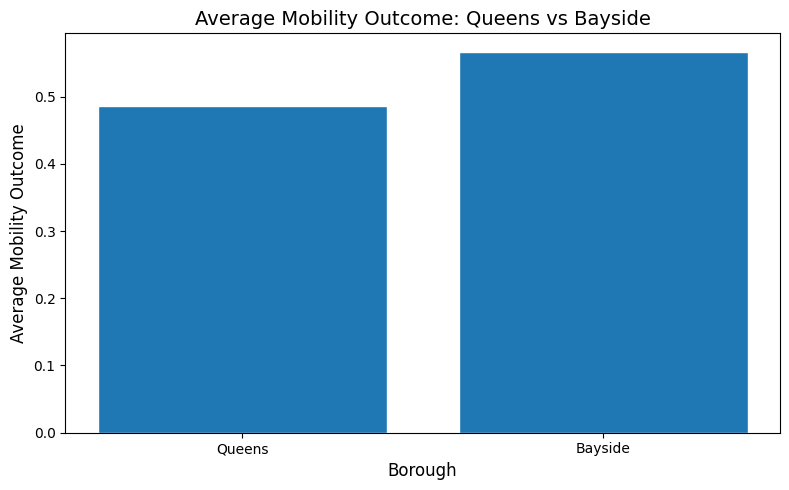

In [51]:
#set colors for each
COLORS = {
    'Bayside':      'steelblue',
    'Queens':        'mediumseagreen',
}

#Make actual bar graph
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    ['Queens', 'Bayside'],
    [boro_stats['mean'], nbhd_stats['mean']],
    edgecolor='white'
)
#text, x and y label, etc
ax.set_xlabel('Borough', fontsize=12)
ax.set_ylabel('Average Mobility Outcome', fontsize=12)
ax.set_title('Average Mobility Outcome: Queens vs Bayside', fontsize=14)
plt.tight_layout()
plt.savefig('hc07__per_borough.png', dpi=150)

plt.show()


This bar graph aids in visualizing the difference between the average mobility outcomes between Queens Bayside. As you can see, the average mobility outcomes in Bayside is higher compared to Queens.

### Distribution of Mobility Outcomes

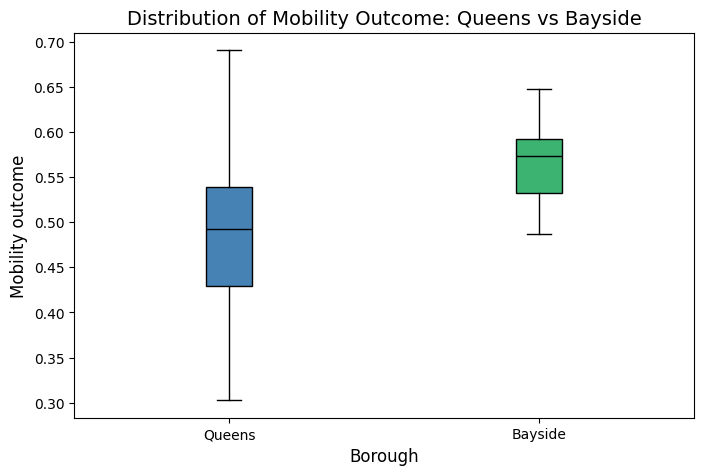

In [23]:
std_spread = [queens['kfr_pooled_pooled_p25'].dropna(),
    my_nbhd['kfr_pooled_pooled_p25'].dropna()]

#Make actual boxplot
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
              std_spread,
              patch_artist=True,
              medianprops={'color': 'black', 'linewidth': 1}
              )
#set color
box['boxes'][0].set_facecolor('steelblue')
box['boxes'][1].set_facecolor('mediumseagreen')

#text, x and y label, etc
ax.set_xlabel('Borough', fontsize=12)
ax.set_ylabel('Mobility outcome', fontsize=12)
ax.set_title('Distribution of Mobility Outcome: Queens vs Bayside', fontsize=14)
plt.savefig('hc07__per_borough.png', dpi=150)
ax.set_xticks([1, 2], labels=['Queens', 'Bayside'])

plt.show()

This box plot shows us the distribution comparing Queens and Bayside. Bayside has a much smaller distribution compared to Queens which means that the average mobility outcomes in Bayside vary far less.

### Individual Census Tracts

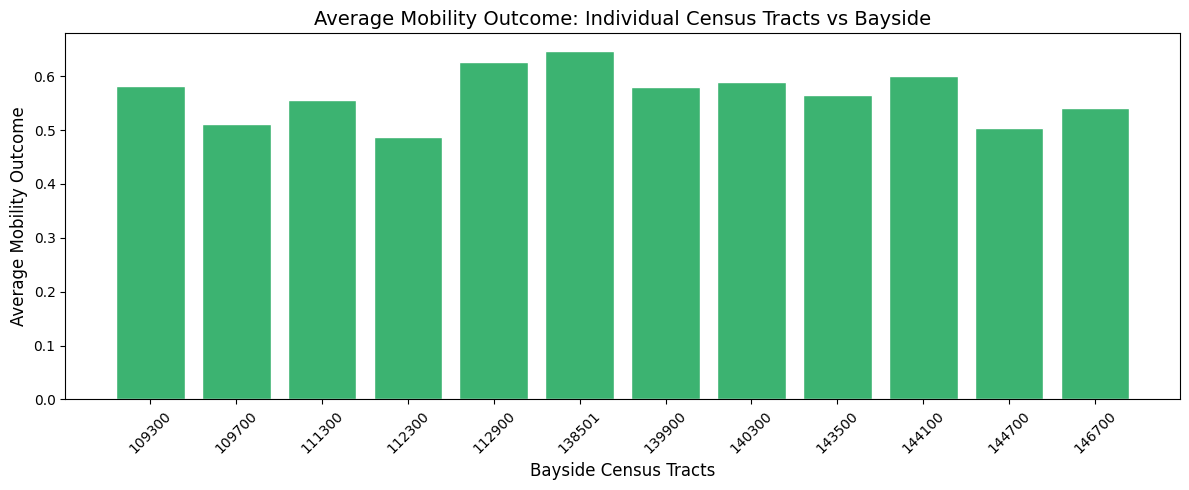

In [48]:
tract_means = my_nbhd.groupby('tract')['kfr_pooled_pooled_p25'].mean()

fig, ax = plt.subplots(figsize=(12, 5))

tract_positions = range(len(tract_means))

ax.bar(
    tract_positions,
    tract_means.values,
    color='mediumseagreen',
    edgecolor='white'
)

# Text, x and y labels, etc.
ax.set_xlabel('Bayside Census Tracts', fontsize=12)
ax.set_ylabel('Average Mobility Outcome', fontsize=12)

ax.set_title(
    'Average Mobility Outcome: Individual Census Tracts vs Bayside',
    fontsize=14
)

ax.set_xticks(tract_positions, labels=tract_means.index)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('hc07_per_borough.png', dpi=150)
plt.show()


This bar graph is comparing the average mobility outcomes for each individual census tract in Bayside. They slightly vary but mostly they are within the 0.5-0.6 range.

### Distribution Within Bayside

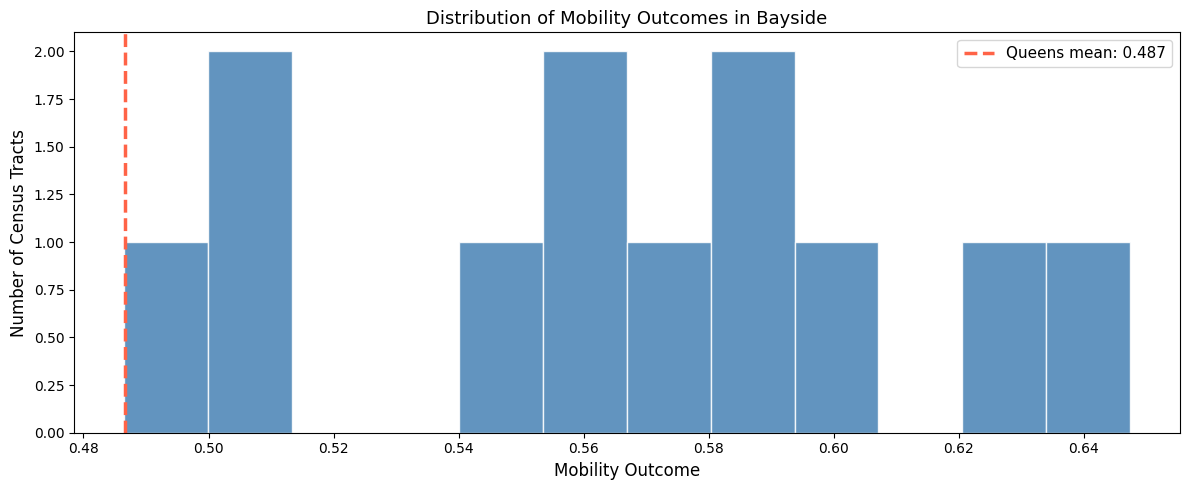

In [53]:


fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(my_nbhd['kfr_pooled_pooled_p25'].dropna(), bins=12,
        color='steelblue', edgecolor='white', alpha=0.85)

ax.axvline(queens_mean, color='tomato', linewidth=2.5, linestyle='--',
           label=f'Queens mean: {queens_mean:.3f}')

ax.set_xlabel('Mobility Outcome', fontsize=12)
ax.set_ylabel('Number of Census Tracts', fontsize=12)
ax.set_title('Distribution of Mobility Outcomes in Bayside', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('hc07_nyc_histogram.png', dpi=150)
plt.show()

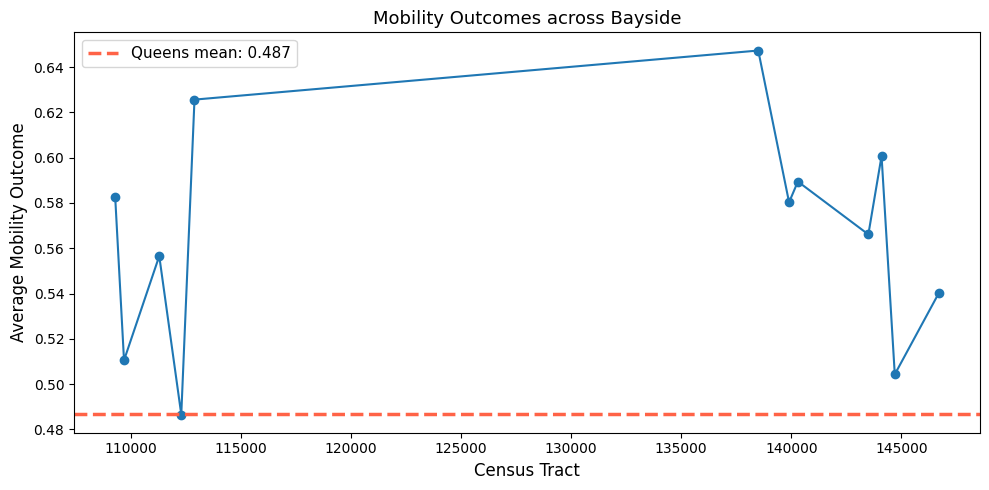

In [54]:


fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(tract_means.index, tract_means.values, marker='o')

ax.axhline(queens_mean, color='tomato', linewidth=2.5, linestyle='--',
           label=f'Queens mean: {queens_mean:.3f}')

ax.set_xlabel('Census Tract', fontsize=12)
ax.set_ylabel('Average Mobility Outcome', fontsize=12)
ax.set_title('Mobility Outcomes across Bayside', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('hc07_nyc_histogram.png', dpi=150)
plt.show()

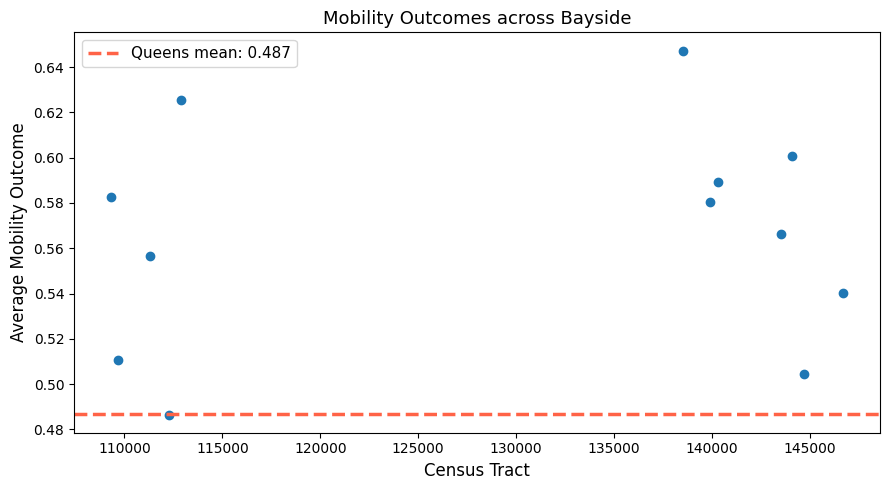

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(tract_means.index, tract_means.values)

ax.axhline(queens_mean, color='tomato', linewidth=2.5, linestyle='--',
           label=f'Queens mean: {queens_mean:.3f}')

ax.set_xlabel('Census Tract', fontsize=12)
ax.set_ylabel('Average Mobility Outcome', fontsize=12)
ax.set_title('Mobility Outcomes across Bayside', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('hc07_nyc_histogram.png', dpi=150)
plt.show()

This histogram shows us the mobility outcomes in each individual census tract and the average mobility outcomes in Queens. This allows us to visualize where most census tracts are with their mobility outcomes and how spread out the results are. According to the histogram, Bayside mostly has close mobility outcomes. The line graph allows us to clearly see the difference between census tracts mobility outcomes. And finally the scatter plot shows us clearly, which census tract is above or below the average mobility outcome for Queens.


### Extra Credit

In comparison to the median incomes in the HC4 assignment, the graph on distribution between census tracts show that the median outcome for these neighborhoods are quite accurate. Since the median income for Queens is around $81,000, the graph seems to be accurate.

### Conclusion

As indicated by the data,the average mobility outcome for Bayside is higher than Queens, the distribution of outcomes is a lot lower, and the distribution between census tracts is lower as well. This overall shows that Bayside is on the higher side of outcome compared to other neighborhoods in Queens and varies less in outcome as well. Factors that may have affected this is education quality and acces, employment opportunities, and community resources.